# 04 — Cartes d'occupation du sol et indicateurs
**Entrées :** `data/s2_{2021,2022,2025}.tif` et `data/feux_effis_2022.tif` et `data/hansen_perte_annee.tif` (notebook 01), `data/config_patchs.json` et `data/patchs_test.npz` (notebook 02), `modeles/<essai>.pt` (notebook 03).

**Ce que fait ce notebook :**
1. Applique le UNet à **toute la zone** pour 2021, 2022 et 2025 (fenêtre glissante avec recouvrement)
2. Vérifie la carte 2021 prédite contre WorldCover
3. Calcule un indice spectral indépendant, le **dNBR**, pour repérer les zones brûlées, et s'en sert pour **valider** la classe « Sol nu / brûlé » prédite en 2022
4. Construit les indicateurs : surfaces par classe, transitions, forêt perdue, reprise de la végétation, fragmentation
5. Produit les cartes et graphiques pour le rapport (suffixés par le nom de l'essai)

## 0. Imports

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import rioxarray
import torch
from scipy import ndimage

from unet import UNet

DEVICE = torch.device("mps" if torch.backends.mps.is_available()
                      else "cuda" if torch.cuda.is_available() else "cpu")
print("Calcul sur :", DEVICE)

Calcul sur : mps


## 1. Paramètres

In [2]:
DATA_DIR = Path("data")
FIG_DIR = Path("figures")
MODELE_DIR = Path("modeles")
FIG_DIR.mkdir(exist_ok=True)

NOM_ESSAI = "unet_2021_seul"          # le modèle à utiliser (nom donné dans le notebook 03)
ANNEES = ["2021", "2022", "2025"]

TUILE = 256                      # taille des fenêtres de prédiction
PAS = 192                        # décalage entre fenêtres (recouvrement de 64 pixels)
BATCH = 16

RESOLUTION = 10                  # m
HA_PAR_PIXEL = RESOLUTION**2 / 10_000

# Seuil dNBR au-delà duquel un pixel est considéré comme brûlé.
# Classes de sévérité usuelles (Key & Benson, USGS) : < 0,10 non brûlé ; 0,10-0,27 faible ;
# 0,27-0,44 modérée-faible ; 0,44-0,66 modérée-forte ; > 0,66 forte.
SEUIL_DNBR = 0.27
SEUIL_NON_BRULE = 0.10
SURFACE_MIN_BRULE_HA = 1.0      # on ignore les « zones brûlées » plus petites (pixels isolés, bruit)

## 2. Chargement du modèle et de la configuration

In [3]:
with open(DATA_DIR / "config_patchs.json") as f:
    CONFIG = json.load(f)

IGNORE = CONFIG["ignore"]
CLASSES = {int(k): v for k, v in CONFIG["classes"].items()}
NOMS = [CLASSES[k]["nom"] for k in sorted(CLASSES)]
N_CLASSES = len(NOMS)
CMAP = ListedColormap([CLASSES[k]["couleur"] for k in sorted(CLASSES)])
FORET = NOMS.index("Forêt")
VEG_BASSE = NOMS.index("Végétation basse")
BRULE = NOMS.index("Sol nu / brûlé")
MOY = np.array(CONFIG["moyenne"], dtype=np.float32)[:, None, None]
ECT = np.array(CONFIG["ecart_type"], dtype=np.float32)[:, None, None]

point = torch.load(MODELE_DIR / f"{NOM_ESSAI}.pt", map_location=DEVICE)
modele = UNet(point["n_bandes"], point["n_classes"], base=point["base"]).to(DEVICE)
modele.load_state_dict(point["etat"])
modele.eval()
print(f"Modèle {NOM_ESSAI} (époque {point['epoque']}) chargé")

Modèle unet_2021_seul (époque 45) chargé


## 3. Prédiction sur toute la zone
L'image entière est trop grande pour passer d'un coup dans le réseau. On la parcourt avec des **fenêtres de 256 × 256 qui se recouvrent**. Dans chaque fenêtre, les pixels du centre comptent plus que ceux des bords (pondération en cloche), car le UNet voit moins de contexte près des bords. Cela évite les effets de « damier » aux jonctions.

In [4]:
def poids_fenetre(t):
    h = np.hanning(t) * 0.9 + 0.1
    return np.outer(h, h).astype(np.float32)


def taille_paddee(n):
    return TUILE + int(np.ceil(max(n - TUILE, 0) / PAS)) * PAS


def predire(chemin):
    """Renvoie (carte des classes uint8, DataArray source pour les coordonnées)."""
    da = rioxarray.open_rasterio(chemin)
    brut = da.values
    sans_donnee = (brut == 0).all(axis=0)
    x = (brut.astype(np.float32) / 10000 - MOY) / ECT

    _, H, W = x.shape
    Hp, Wp = taille_paddee(H), taille_paddee(W)
    x = np.pad(x, ((0, 0), (0, Hp - H), (0, Wp - W)), mode="edge")

    probas = np.zeros((N_CLASSES, Hp, Wp), dtype=np.float32)
    total = np.zeros((Hp, Wp), dtype=np.float32)
    w = poids_fenetre(TUILE)
    positions = [(i, j) for i in range(0, Hp - TUILE + 1, PAS) for j in range(0, Wp - TUILE + 1, PAS)]

    with torch.no_grad():
        for k in range(0, len(positions), BATCH):
            lot = positions[k:k + BATCH]
            tuiles = np.stack([x[:, i:i + TUILE, j:j + TUILE] for i, j in lot])
            p = torch.softmax(modele(torch.from_numpy(tuiles).to(DEVICE)), dim=1).cpu().numpy()
            for (i, j), pi in zip(lot, p):
                probas[:, i:i + TUILE, j:j + TUILE] += pi * w
                total[i:i + TUILE, j:j + TUILE] += w

    carte = probas.argmax(0)[:H, :W].astype(np.uint8)
    carte[sans_donnee] = IGNORE
    return carte, da


cartes, sources = {}, {}
for annee in ANNEES:
    cartes[annee], sources[annee] = predire(DATA_DIR / f"s2_{annee}.tif")
    print(f"{annee} : carte {cartes[annee].shape}")

# Sauvegarde en GeoTIFF (mêmes coordonnées que les images)
for annee, carte in cartes.items():
    ref = sources[annee].isel(band=0)
    out = ref.copy(data=carte)
    out.attrs.pop("long_name", None)   # les noms des 6 bandes ne s'appliquent plus
    out = out.rio.write_nodata(IGNORE)
    out.rio.to_raster(DATA_DIR / f"occupation_{NOM_ESSAI}_{annee}.tif", compress="deflate")
print(f"-> data/occupation_{NOM_ESSAI}_{{2021,2022,2025}}.tif")

2021 : carte (4650, 7674)


2022 : carte (4650, 7674)


2025 : carte (4650, 7674)


-> data/occupation_unet_2021_seul_{2021,2022,2025}.tif


## 4. Cartes d'occupation du sol prédites

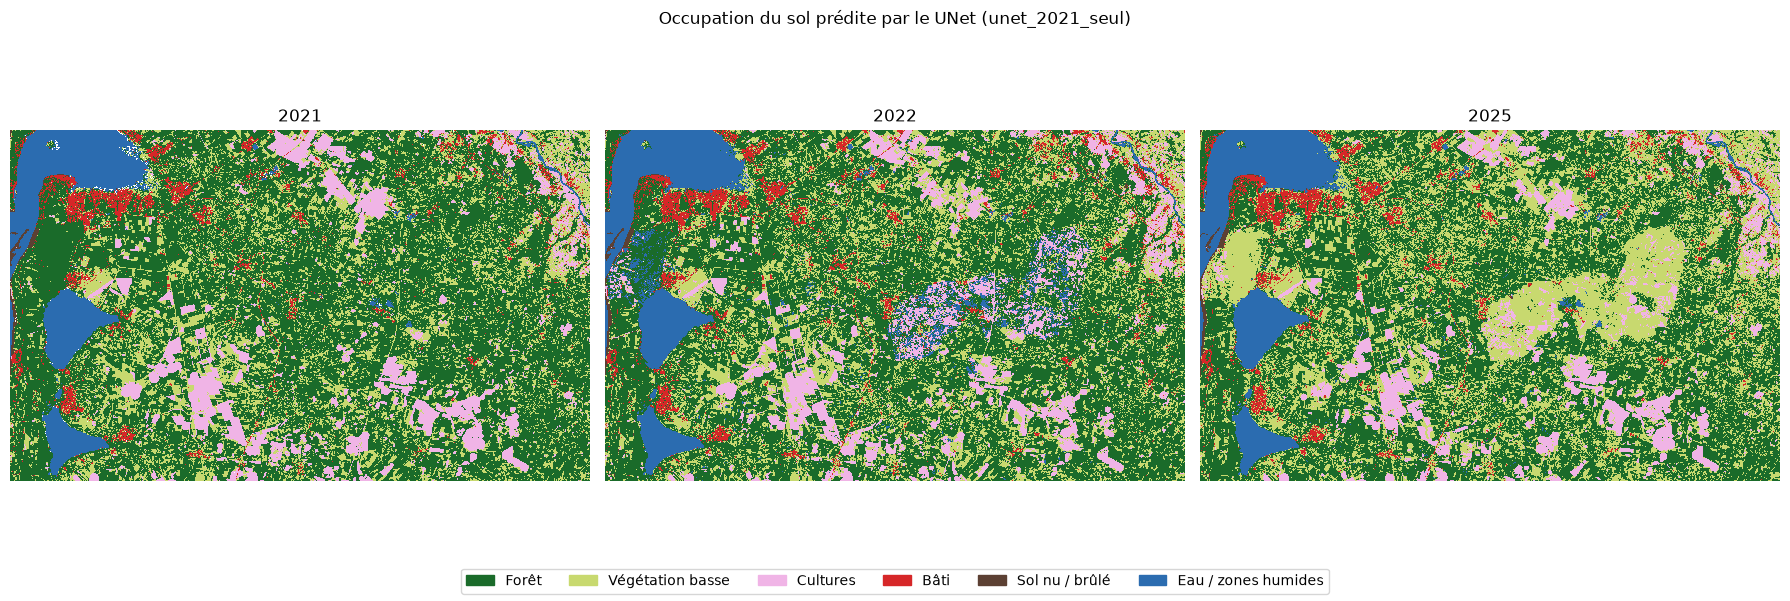

In [5]:
H, W = cartes["2021"].shape
pas_aff = max(1, max(H, W) // 2000)          # sous-échantillonnage pour l'affichage
legende_classes = [Patch(color=CLASSES[k]["couleur"], label=NOMS[k]) for k in range(N_CLASSES)]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, annee in zip(axes, ANNEES):
    ax.imshow(np.ma.masked_equal(cartes[annee][::pas_aff, ::pas_aff], IGNORE),
              cmap=CMAP, vmin=0, vmax=N_CLASSES - 1, interpolation="nearest")
    ax.set_title(annee)
    ax.axis("off")
fig.legend(handles=legende_classes, loc="lower center", ncol=N_CLASSES)
fig.suptitle(f"Occupation du sol prédite par le UNet ({NOM_ESSAI})")
plt.tight_layout(rect=(0, 0.06, 1, 0.97))
plt.savefig(FIG_DIR / f"occupation_3_annees_{NOM_ESSAI}.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Contrôle : carte 2021 prédite contre WorldCover 2021
Attention, ce score est **optimiste** : la zone contient les patchs d'entraînement. Le vrai score de généralisation est celui du jeu de test (notebook 03). Ce contrôle sert surtout à vérifier que la prédiction sur toute la zone n'a pas de défaut (décalage, damier, bords).

In [6]:
wc = rioxarray.open_rasterio(DATA_DIR / "worldcover_2021.tif").squeeze("band", drop=True).values
ref = np.full(wc.shape, IGNORE, dtype=np.uint8)
for k, v in CLASSES.items():
    ref[np.isin(wc, v["worldcover"])] = k

ok = (ref != IGNORE) & (cartes["2021"] != IGNORE)
accord = (ref[ok] == cartes["2021"][ok]).mean()
print(f"Accord UNet 2021 / WorldCover 2021 sur toute la zone : {accord * 100:.1f} %")

Accord UNet 2021 / WorldCover 2021 sur toute la zone : 89.0 %


## 6. Indice spectral indépendant : le dNBR
Le **NBR** (*Normalized Burn Ratio*) = (PIR − SWIR2) / (PIR + SWIR2), soit (B08 − B12) / (B08 + B12). Il est élevé sur une végétation saine et chute après un feu.

Le **dNBR** = NBR avant − NBR après. Plus il est élevé, plus le feu a été sévère.

Il ne dépend pas du UNet : il sert de **validation indépendante**, et permet de séparer les pertes de forêt dues aux feux de celles dues à d'autres causes (coupes rases notamment).

Surface avec dNBR > 0.27 : 86,726 ha


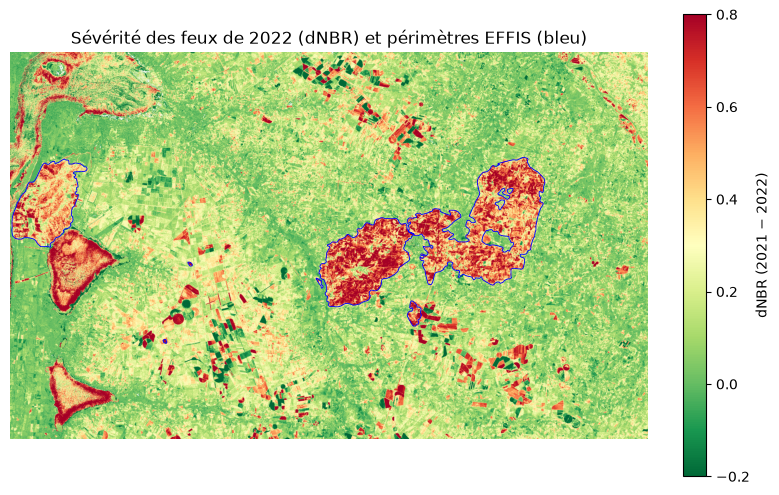

In [7]:
BANDES = CONFIG["bandes"]
i_pir, i_swir2 = BANDES.index("B08"), BANDES.index("B12")


def nbr(annee):
    v = sources[annee].values.astype(np.float32)
    pir, swir2 = v[i_pir], v[i_swir2]
    with np.errstate(divide="ignore", invalid="ignore"):
        r = (pir - swir2) / (pir + swir2)
    r[(v == 0).all(axis=0)] = np.nan
    return r


dnbr = nbr("2021") - nbr("2022")
brule = dnbr > SEUIL_DNBR

# Nettoyage : on retire les groupes de pixels brûlés trop petits pour être un vrai feu
etiq, n = ndimage.label(brule, structure=np.ones((3, 3)))
tailles = np.bincount(etiq.ravel()) * HA_PAR_PIXEL
garder = tailles >= SURFACE_MIN_BRULE_HA
garder[0] = False
brule = garder[etiq]
print(f"Surface avec dNBR > {SEUIL_DNBR} : {brule.sum() * HA_PAR_PIXEL:,.0f} ha")

feux_effis = rioxarray.open_rasterio(DATA_DIR / "feux_effis_2022.tif").squeeze("band", drop=True).values == 1
perte_hansen = rioxarray.open_rasterio(DATA_DIR / "hansen_perte_annee.tif").squeeze("band", drop=True).values

fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(dnbr[::pas_aff, ::pas_aff], cmap="RdYlGn_r", vmin=-0.2, vmax=0.8)
ax.contour(feux_effis[::pas_aff, ::pas_aff], levels=[0.5], colors="blue", linewidths=0.6)
plt.colorbar(im, ax=ax, fraction=0.035, label="dNBR (2021 − 2022)")
ax.set_title("Sévérité des feux de 2022 (dNBR) et périmètres EFFIS (bleu)")
ax.axis("off")
plt.savefig(FIG_DIR / "dnbr_2021_2022.png", dpi=200, bbox_inches="tight")
plt.show()

## 6 bis. Validation indépendante de la classe « Sol nu / brûlé » par le dNBR
Le dNBR n'a servi **ni à l'entraînement ni au choix du modèle** : on peut donc l'utiliser comme référence indépendante. On compare, parmi les pixels prédits en forêt en 2021 :

- **Rappel dNBR** : part des pixels brûlés selon le dNBR (> 0,27) que le UNet classe « Sol nu / brûlé » en 2022 ;
- **Précision dNBR** : part des pixels classés « Sol nu / brûlé » en 2022 qui sont brûlés selon le dNBR.

Ces scores sont calculés sur toute la zone, puis sur la **zone de test seule** (patchs jamais vus à l'entraînement). Sur toute la zone, le modèle a appris les feux à partir des périmètres EFFIS des patchs d'entraînement : le score y est optimiste. Le score de la zone de test est le plus honnête.

On mesure aussi la qualité des étiquettes elles-mêmes : la part des périmètres EFFIS où le dNBR est < 0,10 (îlots non brûlés, étiquetés « brûlé » à tort).

Enfin, on sépare la zone de test **dans** et **hors** des périmètres EFFIS. Le dNBR réagit à toute perte de végétation, pas seulement aux feux : hors des périmètres, un dNBR > 0,27 correspond surtout à des coupes rases, à la sécheresse de l'été 2022 ou au décalage de saison entre les fenêtres 2021 (août-septembre) et 2022 (septembre-mi-octobre). La carte Hansen des pertes forestières (indépendante du dNBR) permet de vérifier la part de ces faux « feux » qui sont des coupes de 2021-2022. Le rappel « dans EFFIS » mesure donc la détection des feux, et le rappel « hors EFFIS » mesure à quel point le modèle **évite** d'appeler « brûlé » ce qui n'a pas brûlé.

In [8]:
P = CONFIG["taille_patch"]
zone_test = np.zeros(cartes["2021"].shape, dtype=bool)
for i, j in np.load(DATA_DIR / "patchs_test.npz")["positions"]:
    zone_test[i*P:(i+1)*P, j*P:(j+1)*P] = True


def ha(m):
    return m.sum() * HA_PAR_PIXEL


valide_dnbr = ~np.isnan(dnbr) & (cartes["2021"] != IGNORE) & (cartes["2022"] != IGNORE)
foret_21 = (cartes["2021"] == FORET) & valide_dnbr
pred_brule_22 = cartes["2022"] == BRULE

# Découpage dans / hors des périmètres EFFIS : hors périmètres, un dNBR élevé signale surtout
# autre chose qu'un feu (coupe rase, sécheresse de 2022, décalage de saison entre les deux fenêtres)
zones = {
    "toute la zone": np.ones_like(zone_test),
    "zone de test": zone_test,
    "zone de test, dans EFFIS": zone_test & feux_effis,
    "zone de test, hors EFFIS": zone_test & ~feux_effis,
}
validation = {}
for nom, zone in zones.items():
    f = foret_21 & zone
    vp = ha(f & brule & pred_brule_22)
    validation[nom] = {
        "forêt 2021 brûlée selon dNBR (ha)": ha(f & brule),
        "forêt 2021 prédite brûlée en 2022 (ha)": ha(f & pred_brule_22),
        "rappel dNBR (%)": vp / max(ha(f & brule), 1e-9) * 100,
        "précision dNBR (%)": vp / max(ha(f & pred_brule_22), 1e-9) * 100,
    }
validation = pd.DataFrame(validation).round(1)
display(validation)

dnbr_effis = dnbr[feux_effis & ~np.isnan(dnbr)]
qualite_effis = {
    "surface des périmètres EFFIS (ha)": ha(feux_effis),
    "part avec dNBR > 0,27 (%)": (dnbr_effis > SEUIL_DNBR).mean() * 100,
    "part avec dNBR < 0,10, îlots non brûlés probables (%)": (dnbr_effis < SEUIL_NON_BRULE).mean() * 100,
    "part de la surface dNBR > 0,27 située dans un périmètre EFFIS (%)": ha(brule & feux_effis) / max(ha(brule), 1e-9) * 100,
    "forêt 2021 hors EFFIS avec dNBR > 0,27 (ha)": ha(foret_21 & brule & ~feux_effis),
    "  dont coupes Hansen 2021-2022 (%)": ha(foret_21 & brule & ~feux_effis & np.isin(perte_hansen, [21, 22]))
                                          / max(ha(foret_21 & brule & ~feux_effis), 1e-9) * 100,
}
pd.Series(qualite_effis).round(1).to_frame("valeur")

,toute la zone,zone de test,"zone de test, dans EFFIS","zone de test, hors EFFIS"
forêt 2021 brûlée selon dNBR (ha),29741.9,6254.1,4440.3,1813.8
forêt 2021 prédite brûlée en 2022 (ha),21.7,0.1,0.0,0.1
rappel dNBR (%),0.1,0.0,0.0,0.0
précision dNBR (%),94.0,42.9,0.0,50.0


,valeur
surface des périmètres EFFIS (ha),26866.9
"part avec dNBR > 0,27 (%)",87.8
"part avec dNBR < 0,10, îlots non brûlés probables (%)",2.6
"part de la surface dNBR > 0,27 située dans un périmètre EFFIS (%)",27.1
"forêt 2021 hors EFFIS avec dNBR > 0,27 (ha)",11537.0
dont coupes Hansen 2021-2022 (%),19.6


## 7. Indicateur 1 : surfaces par classe et par année

In [9]:
valide = np.all([cartes[a] != IGNORE for a in ANNEES], axis=0)
print(f"Pixels valides les 3 années : {valide.mean() * 100:.1f} % de la zone")

surfaces = pd.DataFrame({
    annee: np.bincount(cartes[annee][valide], minlength=N_CLASSES) * HA_PAR_PIXEL for annee in ANNEES
}, index=NOMS)
parts = (surfaces / surfaces.sum() * 100).round(1)
evolution = surfaces.assign(
    **{"Δ 2021→2022 (ha)": surfaces["2022"] - surfaces["2021"],
       "Δ 2022→2025 (ha)": surfaces["2025"] - surfaces["2022"]}
).round(0)
display(evolution)
display(parts.add_suffix(" (%)"))

Pixels valides les 3 années : 99.8 % de la zone


,2021,2022,2025,Δ 2021→2022 (ha),Δ 2022→2025 (ha)
Forêt,209184.0,189484.0,167285.0,-19700.0,-22199.0
Végétation basse,75933.0,82971.0,119069.0,7038.0,36098.0
Cultures,34170.0,38176.0,31781.0,4007.0,-6395.0
Bâti,11554.0,14006.0,12184.0,2452.0,-1822.0
Sol nu / brûlé,1205.0,1284.0,1196.0,79.0,-88.0
Eau / zones humides,24252.0,30376.0,24781.0,6124.0,-5595.0


,2021 (%),2022 (%),2025 (%)
Forêt,58.7,53.2,47.0
Végétation basse,21.3,23.3,33.4
Cultures,9.6,10.7,8.9
Bâti,3.2,3.9,3.4
Sol nu / brûlé,0.3,0.4,0.3
Eau / zones humides,6.8,8.5,7.0


## 8. Indicateur 2 : matrice de transition 2021 → 2022
Chaque case = surface (ha) qui était dans la classe en ligne en 2021 et se retrouve dans la classe en colonne en 2022. La diagonale = ce qui n'a pas changé.

In [10]:
def transitions(a, b):
    m = valide
    t = np.bincount(N_CLASSES * cartes[a][m] + cartes[b][m], minlength=N_CLASSES**2).reshape(N_CLASSES, N_CLASSES)
    return pd.DataFrame(t * HA_PAR_PIXEL, index=[f"{n} ({a})" for n in NOMS],
                        columns=[f"{n} ({b})" for n in NOMS]).round(0)


display(transitions("2021", "2022"))
display(transitions("2022", "2025"))

,Forêt (2022),Végétation basse (2022),Cultures (2022),Bâti (2022),Sol nu / brûlé (2022),Eau / zones humides (2022)
Forêt (2021),180005.0,18783.0,3622.0,931.0,22.0,5821.0
Végétation basse (2021),8158.0,55431.0,9841.0,2043.0,60.0,400.0
Cultures (2021),1010.0,8287.0,24582.0,158.0,31.0,100.0
Bâti (2021),207.0,334.0,99.0,10829.0,54.0,30.0
Sol nu / brûlé (2021),0.0,34.0,17.0,17.0,1049.0,87.0
Eau / zones humides (2021),104.0,101.0,14.0,27.0,68.0,23938.0


,Forêt (2025),Végétation basse (2025),Cultures (2025),Bâti (2025),Sol nu / brûlé (2025),Eau / zones humides (2025)
Forêt (2022),153155.0,32140.0,3024.0,660.0,10.0,495.0
Végétation basse (2022),12416.0,63861.0,5960.0,556.0,74.0,103.0
Cultures (2022),857.0,15375.0,21692.0,212.0,29.0,11.0
Bâti (2022),173.0,2905.0,207.0,10675.0,24.0,22.0
Sol nu / brûlé (2022),2.0,89.0,26.0,41.0,954.0,172.0
Eau / zones humides (2022),681.0,4698.0,872.0,41.0,105.0,23979.0


## 9. Indicateur 3 : forêt perdue et reprise de la végétation
- **Forêt perdue en 2022** : forêt en 2021, plus forêt en 2022.
- **Part attribuable aux feux** : la forêt perdue qui a aussi un dNBR élevé.
- **Devenir en 2025** de la forêt perdue : forêt de nouveau, végétation basse (repousse ou replantation jeune), toujours sans végétation (sol nu / brûlé), ou autre.

In [11]:
f21, f22, f25 = (cartes[a] == FORET for a in ANNEES)
foret_2021 = f21 & valide
perdue = foret_2021 & ~f22
perdue_feu = perdue & brule
perdue_autre = perdue & ~brule

devenir = {
    "Forêt en 2025": perdue & f25,
    "Végétation basse en 2025": perdue & (cartes["2025"] == VEG_BASSE),
    "Sol nu / brûlé en 2025": perdue & (cartes["2025"] == BRULE),
    "Autre (cultures, bâti, eau) en 2025": perdue & ~f25 & ~np.isin(cartes["2025"], [VEG_BASSE, BRULE]),
}

indicateurs = {
    "foret_2021_ha": ha(foret_2021),
    "foret_2022_ha": ha(f22 & valide),
    "foret_2025_ha": ha(f25 & valide),
    "foret_perdue_2022_ha": ha(perdue),
    "foret_devenue_brulee_2022_ha": ha(foret_2021 & (cartes["2022"] == BRULE)),
    "taux_perte_2021_2022_pct": ha(perdue) / max(ha(foret_2021), 1e-9) * 100,
    "perte_attribuable_feux_pct": ha(perdue_feu) / max(ha(perdue), 1e-9) * 100,
    "zones_brulees_dnbr_detectees_par_unet_pct": ha(perdue_feu) / max(ha(brule & foret_2021), 1e-9) * 100,
    "nouvelle_perte_2022_2025_ha": ha(f21 & f22 & ~f25 & valide),
    "nouvelle_perte_2022_2025_dans_zones_brulees_dnbr_ha": ha(f21 & f22 & ~f25 & valide & brule),
    # Validation indépendante : la perte 2022 -> 2025 correspond-elle à des pertes Hansen de 2023-2024 ?
    "nouvelle_perte_2022_2025_confirmee_par_hansen_2023_2024_pct":
        ha(f21 & f22 & ~f25 & valide & np.isin(perte_hansen, [23, 24])) / max(ha(f21 & f22 & ~f25 & valide), 1e-9) * 100,
}
for nom, m in devenir.items():
    indicateurs[f"devenir_2025 : {nom} (% de la forêt perdue)"] = ha(m) / max(ha(perdue), 1e-9) * 100
for nom, m in devenir.items():
    indicateurs[f"devenir_2025 des pertes dues aux feux : {nom} (%)"] = ha(m & brule) / max(ha(perdue_feu), 1e-9) * 100

pd.Series(indicateurs).round(1).to_frame("valeur")

,valeur
foret_2021_ha,209183.6
foret_2022_ha,189484.0
foret_2025_ha,167285.3
foret_perdue_2022_ha,29179.0
foret_devenue_brulee_2022_ha,21.7
taux_perte_2021_2022_pct,13.9
perte_attribuable_feux_pct,53.6
zones_brulees_dnbr_detectees_par_unet_pct,52.6
nouvelle_perte_2022_2025_ha,32897.0
nouvelle_perte_2022_2025_dans_zones_brulees_dnbr_ha,10239.4


## 10. Indicateur 4 : fragmentation du massif forestier
Une forêt découpée en nombreux petits îlots est plus fragile qu'un massif continu (biodiversité, continuités écologiques). On compte les **taches de forêt** (pixels de forêt connectés, y compris en diagonale).

In [12]:
def fragmentation(masque):
    etiq, n = ndimage.label(masque, structure=np.ones((3, 3)))
    if n == 0:
        return {"n_taches": 0, "surface_moyenne_ha": 0, "plus_grande_tache_pct": 0, "taches_<_1ha_pct_surface": 0}
    tailles = np.bincount(etiq.ravel())[1:] * HA_PAR_PIXEL
    return {
        "n_taches": int(n),
        "surface_moyenne_ha": tailles.mean(),
        "plus_grande_tache_pct": tailles.max() / tailles.sum() * 100,
        "taches_<_1ha_pct_surface": tailles[tailles < 1].sum() / tailles.sum() * 100,
    }

frag = pd.DataFrame({a: fragmentation((cartes[a] == FORET) & valide) for a in ANNEES}).round(2)
frag

,2021,2022,2025
n_taches,8093.00,14355.00,11594.00
surface_moyenne_ha,25.85,13.20,14.43
plus_grande_tache_pct,61.73,52.70,19.42
taches_<_1ha_pct_surface,0.60,1.03,1.08


## 11. Carte des changements
Synthèse en une carte de la trajectoire de chaque pixel de forêt entre 2021, 2022 et 2025. Le contour noir délimite la forêt 2021 brûlée selon le dNBR (on n'affiche pas le dNBR hors forêt, où il réagit aussi à l'eau et aux récoltes).

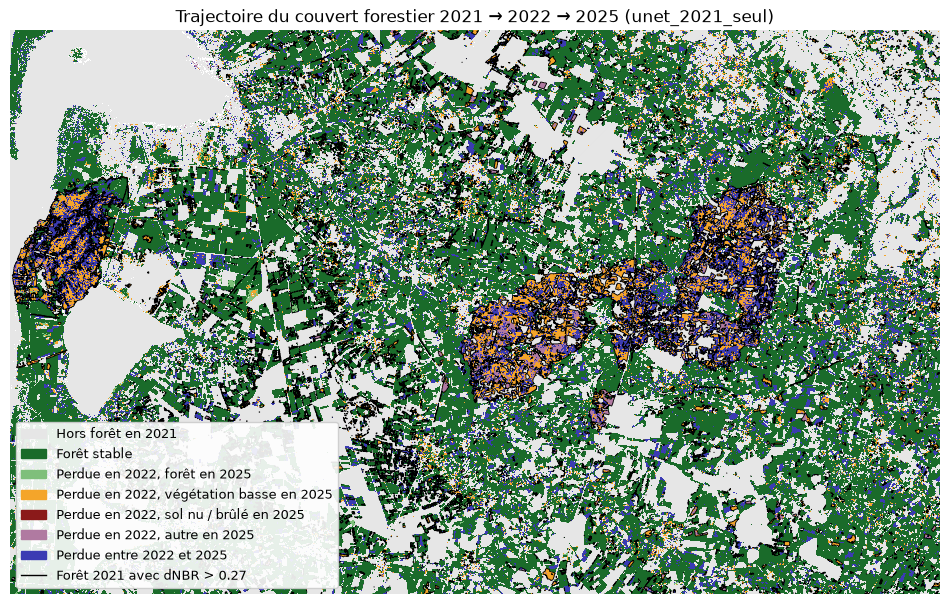

In [13]:
TRAJ = [
    ("Hors forêt en 2021",                               "#e6e6e6"),
    ("Forêt stable",                                     "#1a6b2a"),
    ("Perdue en 2022, forêt en 2025",                    "#7fbf7b"),
    ("Perdue en 2022, végétation basse en 2025",         "#f4a52a"),
    ("Perdue en 2022, sol nu / brûlé en 2025",           "#8b1a1a"),
    ("Perdue en 2022, autre en 2025",                    "#b07aa1"),
    ("Perdue entre 2022 et 2025",                        "#3b3bb3"),
]
traj = np.zeros(cartes["2021"].shape, dtype=np.uint8)
traj[foret_2021 & f22 & f25] = 1
for k, m in enumerate(devenir.values(), start=2):
    traj[m] = k
traj[foret_2021 & f22 & ~f25] = 6
traj[~valide] = IGNORE

ref = sources["2021"].isel(band=0)
out = ref.copy(data=traj)
out.attrs.pop("long_name", None)
out.rio.write_nodata(IGNORE).rio.to_raster(DATA_DIR / f"trajectoires_foret_{NOM_ESSAI}.tif", compress="deflate")

fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(np.ma.masked_equal(traj[::pas_aff, ::pas_aff], IGNORE),
          cmap=ListedColormap([c for _, c in TRAJ]), vmin=0, vmax=len(TRAJ) - 1, interpolation="nearest")
ax.contour((brule & foret_2021)[::pas_aff, ::pas_aff].astype(float), levels=[0.5], colors="black", linewidths=0.6)
handles = [Patch(color=c, label=n) for n, c in TRAJ] + [plt.Line2D([], [], color="black", lw=1, label=f"Forêt 2021 avec dNBR > {SEUIL_DNBR}")]
ax.legend(handles=handles, loc="lower left", fontsize=9, framealpha=0.9)
ax.set_title(f"Trajectoire du couvert forestier 2021 → 2022 → 2025 ({NOM_ESSAI})")
ax.axis("off")
plt.savefig(FIG_DIR / f"carte_trajectoires_foret_{NOM_ESSAI}.png", dpi=200, bbox_inches="tight")
plt.show()

## 12. Graphiques de synthèse

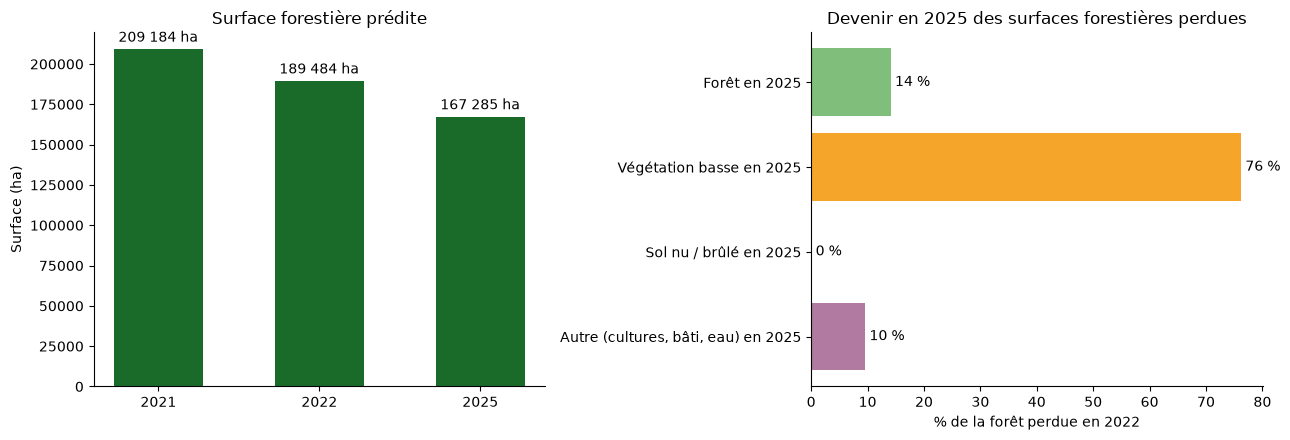

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Surface forestière par année
vals = [indicateurs[f"foret_{a}_ha"] for a in ANNEES]
barres = axes[0].bar(ANNEES, vals, color="#1a6b2a", width=0.55)
axes[0].bar_label(barres, labels=[f"{v:,.0f} ha".replace(",", " ") for v in vals], padding=3)
axes[0].set_ylabel("Surface (ha)")
axes[0].set_title("Surface forestière prédite")

# Devenir en 2025 de la forêt perdue en 2022
noms_dev = list(devenir)
parts_dev = [indicateurs[f"devenir_2025 : {n} (% de la forêt perdue)"] for n in noms_dev]
couleurs_dev = [c for _, c in TRAJ[2:6]]
barres = axes[1].barh(noms_dev, parts_dev, color=couleurs_dev)
axes[1].bar_label(barres, labels=[f"{p:.0f} %" for p in parts_dev], padding=3)
axes[1].invert_yaxis()
axes[1].set_xlabel("% de la forêt perdue en 2022")
axes[1].set_title("Devenir en 2025 des surfaces forestières perdues")

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG_DIR / f"synthese_indicateurs_{NOM_ESSAI}.png", dpi=200, bbox_inches="tight")
plt.show()

## 13. Sauvegarde des indicateurs

In [15]:
sortie = {
    "modele": NOM_ESSAI,
    "seuil_dnbr": SEUIL_DNBR,
    "accord_2021_worldcover_pct": float(accord * 100),
    "validation_dnbr": validation.to_dict(),
    "qualite_perimetres_effis": {k: float(v) for k, v in qualite_effis.items()},
    "indicateurs": {k: float(v) for k, v in indicateurs.items()},
    "fragmentation": frag.to_dict(),
}
with open(DATA_DIR / f"indicateurs_{NOM_ESSAI}.json", "w") as f:
    json.dump(sortie, f, indent=2, ensure_ascii=False, default=float)
evolution.to_csv(DATA_DIR / f"surfaces_par_classe_{NOM_ESSAI}.csv")
print(f"-> data/indicateurs_{NOM_ESSAI}.json, data/surfaces_par_classe_{NOM_ESSAI}.csv")

-> data/indicateurs_unet_2021_seul.json, data/surfaces_par_classe_unet_2021_seul.csv


## 14. Comparaison des indicateurs entre essais
Si le notebook a été exécuté pour plusieurs modèles, ce tableau montre à quel point les indicateurs dépendent du modèle choisi (robustesse des conclusions).

In [16]:
lignes = {}
for f in sorted(DATA_DIR.glob("indicateurs_*.json")):
    r = json.load(open(f))
    ligne = {"accord WorldCover 2021 (%)": r["accord_2021_worldcover_pct"]}
    ligne.update({f"{k} ({z})": v for z, d in r["validation_dnbr"].items() for k, v in d.items() if "%" in k})
    ligne.update(r["indicateurs"])
    lignes[r["modele"]] = ligne
pd.DataFrame(lignes).round(1)

,unet_2021_seul,unet_base,unet_sans_poids
accord WorldCover 2021 (%),89.0,89.1,89.8
rappel dNBR (%) (toute la zone),0.1,64.8,62.3
précision dNBR (%) (toute la zone),94.0,87.0,87.6
rappel dNBR (%) (zone de test),0.0,73.7,71.6
précision dNBR (%) (zone de test),42.9,89.9,90.6
"rappel dNBR (%) (zone de test, dans EFFIS)",0.0,99.8,99.5
"précision dNBR (%) (zone de test, dans EFFIS)",0.0,91.7,91.9
"rappel dNBR (%) (zone de test, hors EFFIS)",0.0,5.6,4.6
"précision dNBR (%) (zone de test, hors EFFIS)",50.0,47.1,52.0
foret_2021_ha,209183.6,196334.6,208182.1


## Notes pour le rapport
- *Methods* : prédiction par fenêtre glissante, définition de chaque indicateur, seuil dNBR (et sa source), pourquoi le dNBR reste une validation indépendante (il n'a servi ni aux étiquettes ni au choix du modèle), pourquoi comparer des cartes **toutes produites par le même modèle** (plutôt que WorldCover pour 2021 et le UNet pour 2022).
- *Results* : validation dNBR (rappel / précision, zone de test), carte des trajectoires, tableau des surfaces, taux de perte, part due aux feux, devenir en 2025, fragmentation. Chaque figure accompagnée d'au moins une valeur chiffrée (exigé par la grille).
- *Discussion* : pertes hors feux (coupes rases, coupes de bois brûlé après 2022) ; hors des feux, le dNBR > 0,27 capte aussi des coupes (vérifié avec Hansen) ; le seuil dNBR change les résultats (tester 0,10 et 0,44) ; erreurs du modèle qui s'additionnent d'une année à l'autre ; la « végétation basse » de 2025 peut être une replantation et non une repousse naturelle ; le dNBR et EFFIS ne sont pas totalement indépendants (EFFIS est aussi tracé à partir d'images satellite), mais le dNBR est calculé par nous, au pixel, sans intervenir dans l'apprentissage.